In [1]:
import os
import sys
import tempfile
from pathlib import Path
from IPython.display import Image, display

# The notebook starts in docs/examples. Keep generated files outside the checkout.
repository = Path.cwd().parents[1]
workspace = tempfile.TemporaryDirectory(prefix="croak-gallery-")
(Path(workspace.name) / "examples").symlink_to(repository / "examples", target_is_directory=True)
sys.path.insert(0, str(repository / "examples"))
os.chdir(workspace.name)

In [2]:
"""Propagate a measured substrate-thickness uncertainty onto the retrieved FWHM.

For a *dispersive* retrieval, croak fits the trace through a forward model that
propagates the field through a substrate of an assumed thickness. When that thickness
is an independently measured input with its own error bar — e.g. ``9.952 ± 0.539`` µm
— the retrieved pulse, and its temporal-intensity FWHM, inherit a **systematic**
uncertainty. For some short, deep-UV pulses this substrate term can exceed the
statistical bootstrap (which is blind to it: every bootstrap replicate reuses the
same fixed thickness).

This example builds a small synthetic dispersive experiment, retrieves it, and then:

* runs :func:`croak.thickness_bootstrap` to get the FWHM error from the thickness prior,
* runs a statistical :func:`croak.parametric_bootstrap` for comparison,
* illustrates a Gaussian quadrature approximation for independent contributions, and
* saves the thickness-sensitivity figure.

Run::

    uv run python examples/example_thickness_uncertainty.py

Writes ``thickness_uncertainty.png`` to the working directory. The manual's session
and uncertainty chapters describe how to apply this analysis to your own measurement.
"""

from __future__ import annotations

from math import hypot

import matplotlib
import numpy as np

matplotlib.use("Agg")

import croak
from croak.maths import wlfreq

# --- substrate prior (the measured glass thickness and its 1σ uncertainty) ----
# The motivating measurement is a *thin* DUV substrate, ~9.952 ± 0.539 µm (≈5.4 % 1σ).
# This self-contained demo instead uses a thicker slab at a longer (near-UV) wavelength
# to illustrate the two uncertainty contributions on a self-contained calculation.
# This is not equivalent to the broadband DUV instrument. The noisy retrieval can
# be biased even when its residual and parametric-bootstrap spread are small;
# compare the known duration below and inspect the temporal profile.
CENTRAL_THICKNESS = 100.0e-6  # L0 (m)
THICKNESS_SIGMA = 5.0e-6  # σ_L (m) — ≈5 %, matching the DUV case's relative error
MATERIAL = "SiO2-Franta"
NPOINTS = 20  # depth-quadrature nodes through the slab


def make_dispersive_experiment() -> dict:
    """Synthesise a short near-UV pulse propagated through ``CENTRAL_THICKNESS``."""
    grid = croak.Grid(256, dt=0.5e-15)
    omega0 = float(wlfreq(300e-9))  # near-UV carrier
    ew = croak.gaussian_pulse(grid, 3e-15)  # transform-limited
    delays = np.linspace(-45e-15, 45e-15, 80)
    trace = croak.maketrace(
        grid.omega,
        delays,
        ew,
        "pg",
        material=MATERIAL,
        thickness=CENTRAL_THICKNESS,
        npoints=NPOINTS,
        omega0=omega0,
    )
    return {"grid": grid, "omega0": omega0, "ew": ew, "delays": delays, "trace": trace}


def main() -> None:
    exp = make_dispersive_experiment()
    grid, omega0, delays = exp["grid"], exp["omega0"], exp["delays"]
    # A touch of detector noise so the *statistical* bootstrap is non-trivial and the
    # comparison with the thickness systematic is meaningful.
    measured = croak.NoiseModel(sigma=0.005).draw(
        exp["trace"], np.random.default_rng(7)
    )

    # --- base dispersive retrieval at the central thickness L0 ---
    result = croak.retrieve(
        measured,
        grid.omega,
        delays,
        "pg",
        guess=exp["ew"],
        omega0=omega0,
        material=MATERIAL,
        thickness=CENTRAL_THICKNESS,
        npoints=NPOINTS,
        maxiters=150,
        progress=False,
        rng=np.random.default_rng(0),
    )
    pr = croak.process_result(result, measured=measured)
    print(
        f"Base retrieval: R = {result.error:.4%},  FWHM = {pr.fwhm_retr / 1e-15:.2f} fs"
    )

    # --- systematic: propagate the measured substrate-thickness prior ---
    thick = croak.thickness_bootstrap(
        result,
        measured,
        central_thickness=CENTRAL_THICKNESS,
        thickness_sigma=THICKNESS_SIGMA,
        material=MATERIAL,
        npoints=NPOINTS,
        n_resamples=40,
        maxiters=120,
        collect_profiles=True,
        rng=np.random.default_rng(0),
    )
    print(thick.summary())

    # --- statistical: parametric bootstrap for comparison (noise from the residual) ---
    stat = croak.parametric_bootstrap(
        result,
        noise=croak.noise_from_residual(measured, result),
        material=MATERIAL,
        thickness=CENTRAL_THICKNESS,
        npoints=NPOINTS,
        n_resamples=40,
        maxiters=120,
        rng=np.random.default_rng(1),
    )
    print(stat.summary())

    # --- total error budget: independent terms add in quadrature ---
    total_pm = hypot(thick.plus_minus, stat.plus_minus)
    print(
        f"Total: FWHM = {thick.point_estimate / 1e-15:.2f} "
        f"± {total_pm / 1e-15:.2f} fs "
        f"(stat ⊕ thickness; thickness {thick.plus_minus / 1e-15:.2f} fs, "
        f"stat {stat.plus_minus / 1e-15:.2f} fs)"
    )

    truth_fwhm = croak.maths.fwhm(grid.t, np.abs(grid.ifft(exp["ew"])) ** 2)
    print(f"Generating FWHM = {truth_fwhm / 1e-15:.2f} fs; compare bias with spread.")
    fig = croak.plot_thickness_sensitivity(thick, truth=truth_fwhm)
    fig.savefig("thickness_uncertainty.png", dpi=110)
    print("Wrote thickness_uncertainty.png")


if __name__ == "__main__":
    main()


# For a saved experimental session, use croak.load_session and croak.replay,
# then propagate its independently calibrated thickness with thickness_bootstrap.
# See the gallery and the manual's saving/session and uncertainty chapters.


Base retrieval: R = 0.3082%,  FWHM = 2.30 fs


FWHM = 2.30 ± 0.75 fs (1σ from substrate thickness 100.000 ± 5.000 µm, systematic, B=40)


FWHM = 2.30 ± 0.04 fs (1σ statistical, parametric, B=40, warm-started; systematic uncertainty not included)
Total: FWHM = 2.30 ± 0.76 fs (stat ⊕ thickness; thickness 0.75 fs, stat 0.04 fs)
Generating FWHM = 3.00 fs; compare bias with spread.
Wrote thickness_uncertainty.png


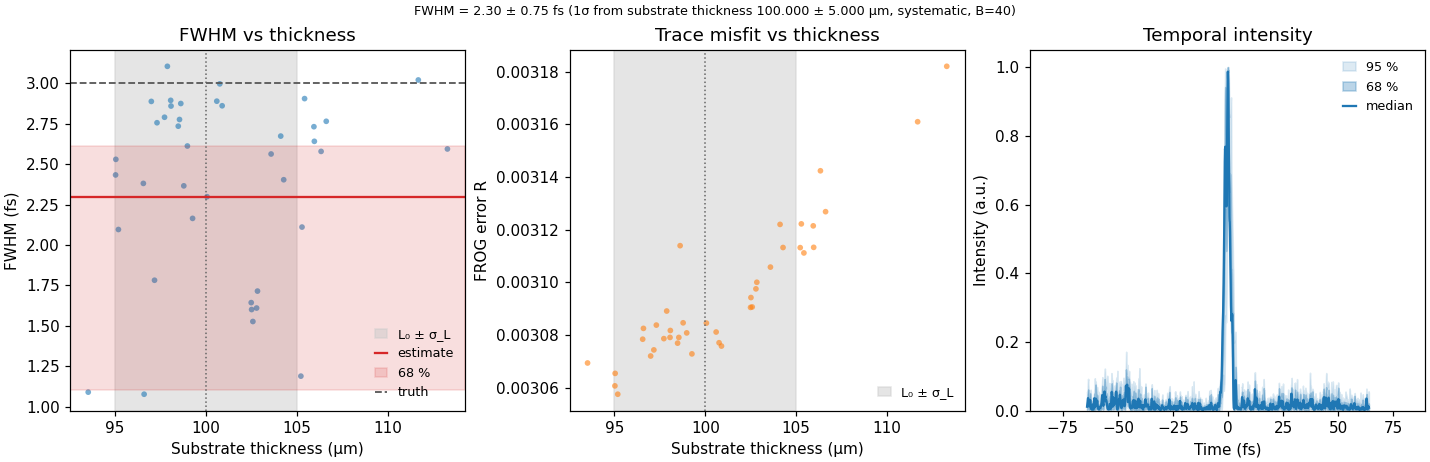

In [3]:
display(Image(filename="thickness_uncertainty.png"))